<a href="https://colab.research.google.com/github/ralph-Jung/AI-Class/blob/main/7%EC%A3%BC%EC%B0%A8/10_26_car_evaluation_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# 1 . 라이브러리 & 데이터 불러오기
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder


df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/car.data.csv", header=None,
    names=["buying", "maint", "doors", "persons", "lug_boot", "safety", "class"])


(1728, 7)
  buying  maint doors persons lug_boot safety  class
0  vhigh  vhigh     2       2    small    low  unacc
1  vhigh  vhigh     2       2    small    med  unacc
2  vhigh  vhigh     2       2    small   high  unacc
3  vhigh  vhigh     2       2      med    low  unacc
4  vhigh  vhigh     2       2      med    med  unacc
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   persons   1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
 6   class     1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB

=== 결측치 ===
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64

중복 행: 0

=== 컬럼별 값 종류 ===
buying : ['vhigh' 'high' 'med' '

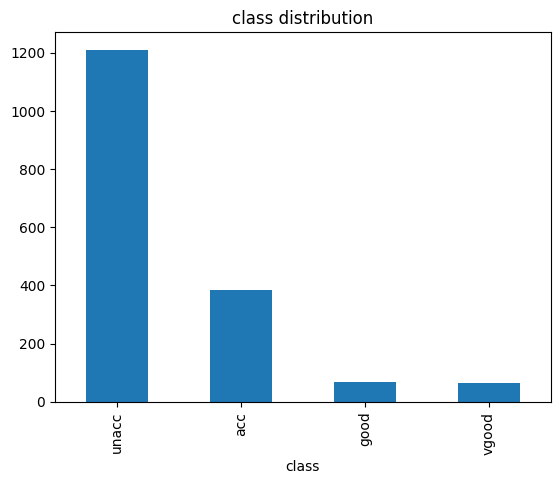

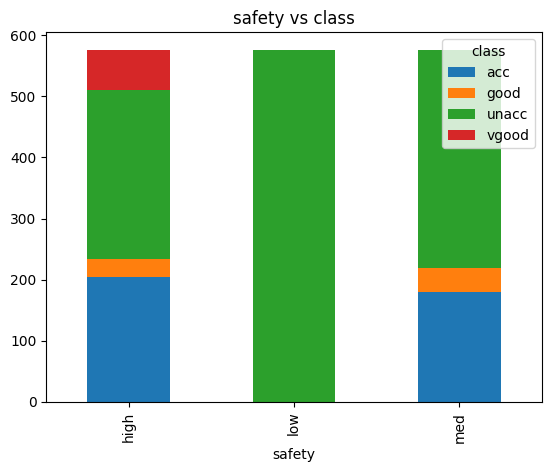

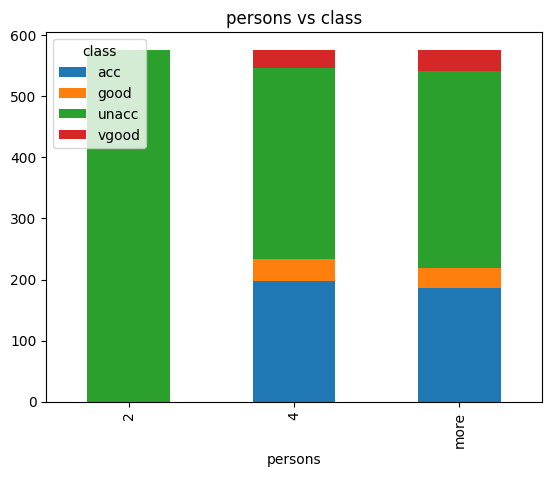

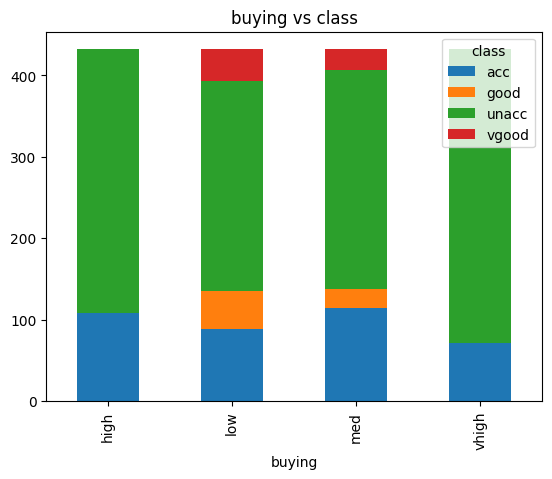

In [3]:
# 2 . EDA
## 기본 구조
print(df.shape)
print(df.head())
df.info()

## 결측치
print("\n=== 결측치 ===")
print(df.isnull().sum())

## 중복
print("\n중복 행:", df.duplicated().sum())

## 이상한 값 확인 (각 컬럼에 어떤 값이 있는지)
print("\n=== 컬럼별 값 종류 ===")
for col in df.columns:
    print(col, ":", df[col].unique())

## 정답(class) 분포
print("\n=== class 분포 ===")
print(df["class"].value_counts())
print(df["class"].value_counts(normalize=True).round(3))

df["class"].value_counts().plot(kind="bar", title="class distribution")
plt.show()

## 특성별로 class가 어떻게 달라지는지
for col in ["safety", "persons", "buying"]:
    pd.crosstab(df[col], df["class"]).plot(kind="bar", stacked=True, title=f"{col} vs class")
    plt.show()

In [4]:
# 3. 전처리
## 결측치 : 처리할게 없음
## 이상치 : 처리할게 없음
## 이상한 값 : 컬럼별 값 종류 확인 결과 없음
## 데이터 타입 : 전부 문자(object) → 원-핫 인코딩 필요
## class 불균형 : unacc 70%, good/vgood 각 4% → 분할 시 stratify로 비율 유지
## 스케일링 : 원-핫 후 0/1 값이라 불필요

feature_cols = ["buying", "maint", "doors", "persons", "lug_boot", "safety"]
X = pd.get_dummies(df[feature_cols]).values.astype("float32")

Y_df = pd.get_dummies(df["class"])
labels = Y_df.columns.tolist()
Y = Y_df.values.astype("float32")
print("클래스 순서:", labels, "| X 모양:", X.shape, "| Y 모양:", Y.shape)


클래스 순서: ['acc', 'good', 'unacc', 'vgood'] | X 모양: (1728, 21) | Y 모양: (1728, 4)


In [5]:
# 4. 학습 / 테스트 분할
# 80% 학습, 20% 테스트 , class 비율 유지
X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, stratify=df["class"], random_state=42
)

print(X_train.shape, y_train.shape)   # (1382, 6) (1382, 4)
print(X_test.shape, y_test.shape)     # (346, 6) (346, 4)

(1382, 21) (1382, 4)
(346, 21) (346, 4)


In [6]:
# 4. 모델 구성
# 다중 분류 + 단일 레이블 → 출력층 softmax, 클래스가 4개라 노드 4개
# 클래스가 acc, good, unacc, vgood 4개
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(4, activation="softmax"),
])

model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,620 (14.14 KB)

 Trainable params: 3,620 (14.14 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# 5. 학습
early = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    epochs=200, batch_size=32,
    validation_split=0.2, callbacks=[early], verbose=1)

Epoch 1/200
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.6253 - loss: 1.0547 - val_accuracy: 0.6823 - val_loss: 0.8774
Epoch 2/200
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7050 - loss: 0.7515 - val_accuracy: 0.6823 - val_loss: 0.7465
Epoch 3/200
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7195 - loss: 0.6093 - val_accuracy: 0.7581 - val_loss: 0.6102
Epoch 4/200
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8036 - loss: 0.4756 - val_accuracy: 0.7870 - val_loss: 0.4883
Epoch 5/200
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8480 - loss: 0.3761 - val_accuracy: 0.8339 - val_loss: 0.4065
Epoch 6/200
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8760 - loss: 0.3103 - val_accuracy: 0.8520 - val_loss: 0.3567
Epoch 7/200
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8950 - loss: 0.2618 - val_accuracy: 0.8700 - val_loss: 0.3122
Epoch 8/200
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9186 - loss: 0.2244 - val_accuracy: 0.8773 - 

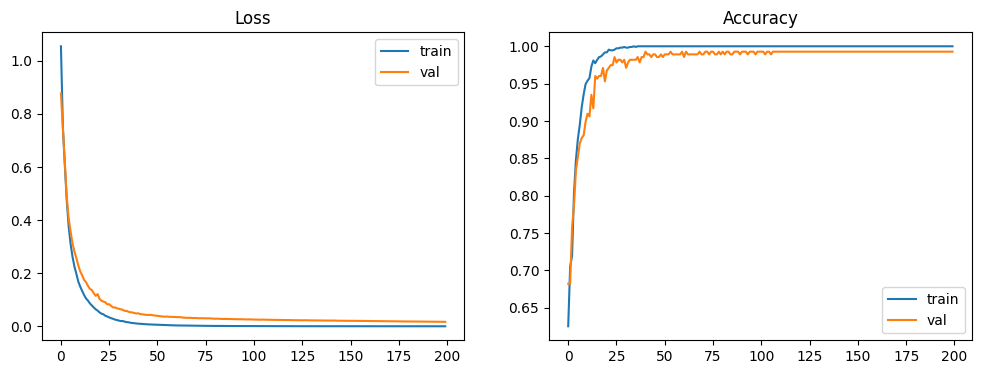

In [8]:
# 6. 학습 곡선 (과적합 여부 확인)
# 과적합 거의 없음 , 학습이 아주 잘됨
# Loss 에서 train 에폭과 유사하게 val 에폭도 줄어드는걸 볼 수 있음
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="val")
axes[0].set_title("Loss"); axes[0].legend()
axes[1].plot(history.history["accuracy"], label="train")
axes[1].plot(history.history["val_accuracy"], label="val")
axes[1].set_title("Accuracy"); axes[1].legend()
plt.show()

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
Accuracy: 1.0
              precision    recall  f1-score   support

         acc       1.00      1.00      1.00        77
        good       1.00      1.00      1.00        14
       unacc       1.00      1.00      1.00       242
       vgood       1.00      1.00      1.00        13

    accuracy                           1.00       346
   macro avg       1.00      1.00      1.00       346
weighted avg       1.00      1.00      1.00       346



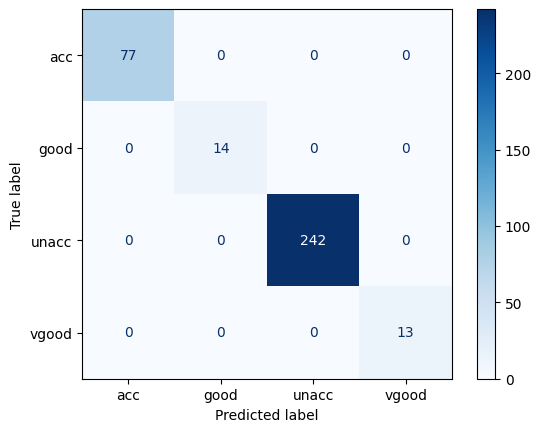

In [10]:
# 7. 평가
y_pred = np.argmax(model.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)
print("Accuracy:", accuracy_score(y_true, y_pred))
print(classification_report(y_true, y_pred, target_names=labels))

ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=labels).plot(cmap="Blues")
plt.show()

In [11]:
# 8. 정확도가 1이 나온거에 대한 의심

## 1. 학습이 끝난 모델로 train 데이터와 test 데이터를 각각 다시 예측해서 정확도 비교
print("train:", model.evaluate(X_train, y_train, verbose=0)[1])
print("test :", model.evaluate(X_test, y_test, verbose=0)[1])

## 2. 데이터 누수 확인
### EDA 를 통해 중복 행이 없음을 확인했고 train_test_split을 통해서 train 과 test 를 겹치는 행 없이 나누기 때문에
### train/test에 같은 데이터가 섞이지 않음

###  + 입력 컬럼에 정답(class)이 포함되지 않음
print(pd.get_dummies(df[feature_cols]).columns.tolist())

## 3. 클래스별 성능
### f1-score 를 봤을 때 1 이라는 것을 통해서 다수의 클래스로 예측한 것이 아닌 소수의 클래스도 잘 예측했음을 알 수 있다

y_pred = np.argmax(model.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)
print(classification_report(y_true, y_pred, target_names=labels))

train: 0.9985527992248535
test : 1.0
['buying_high', 'buying_low', 'buying_med', 'buying_vhigh', 'maint_high', 'maint_low', 'maint_med', 'maint_vhigh', 'doors_2', 'doors_3', 'doors_4', 'doors_5more', 'persons_2', 'persons_4', 'persons_more', 'lug_boot_big', 'lug_boot_med', 'lug_boot_small', 'safety_high', 'safety_low', 'safety_med']
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
              precision    recall  f1-score   support

         acc       1.00      1.00      1.00        77
        good       1.00      1.00      1.00        14
       unacc       1.00      1.00      1.00       242
       vgood       1.00      1.00      1.00        13

    accuracy                           1.00       346
   macro avg       1.00      1.00      1.00       346
weighted avg       1.00      1.00      1.00       346

